# Figure 6

In [4]:
from riskhistory.format import rcParams
from riskhistory.data import (
    load_loo_comparison,
    DATASET_LABELS,
)
import numpy as np
import matplotlib.pyplot as plt

DATASETS = ["equalIndifference", "equalRange", "sheng2020"]

### Helper functions

In [5]:
def plot_elpd_improvement(ax, diffs, x_labels, color, show_ylabel=True):
    """Bar chart of ELPD-LOO improvement over a baseline model, one bar per
    arousal mechanism, sorted lowest to greatest. Positive = better fit than
    baseline."""
    order = np.argsort(diffs)
    diffs = np.asarray(diffs)[order]
    x_labels = np.asarray(x_labels)[order]
    x_pos = np.arange(len(diffs))

    ax.bar(x_pos, diffs, color=color, width=0.6, zorder=3)
    ax.axhline(0, color="black", linestyle="--", linewidth=1.5, zorder=2)

    ax.set_xticks(x_pos)
    ax.set_xticklabels(x_labels)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    if show_ylabel:
        ax.set_ylabel("ELPD-LOO improvement\nover Pupil baseline model")

### 1x3 figure: ELPD-LOO improvement of each arousal mechanism over the Pupil baseline model
Columns = datasets. Bars are the `arousal_mechanisms` group from `compare_models.py`, computed from `elpd_loo` directly (relative to `BASELINE_MODEL`) rather than the table's own `elpd_diff`, which is relative to the rank-0 model. Baseline model itself is omitted (its improvement over itself is trivially 0). Bars within each panel are sorted lowest to greatest independently, so mechanism order can differ across datasets.

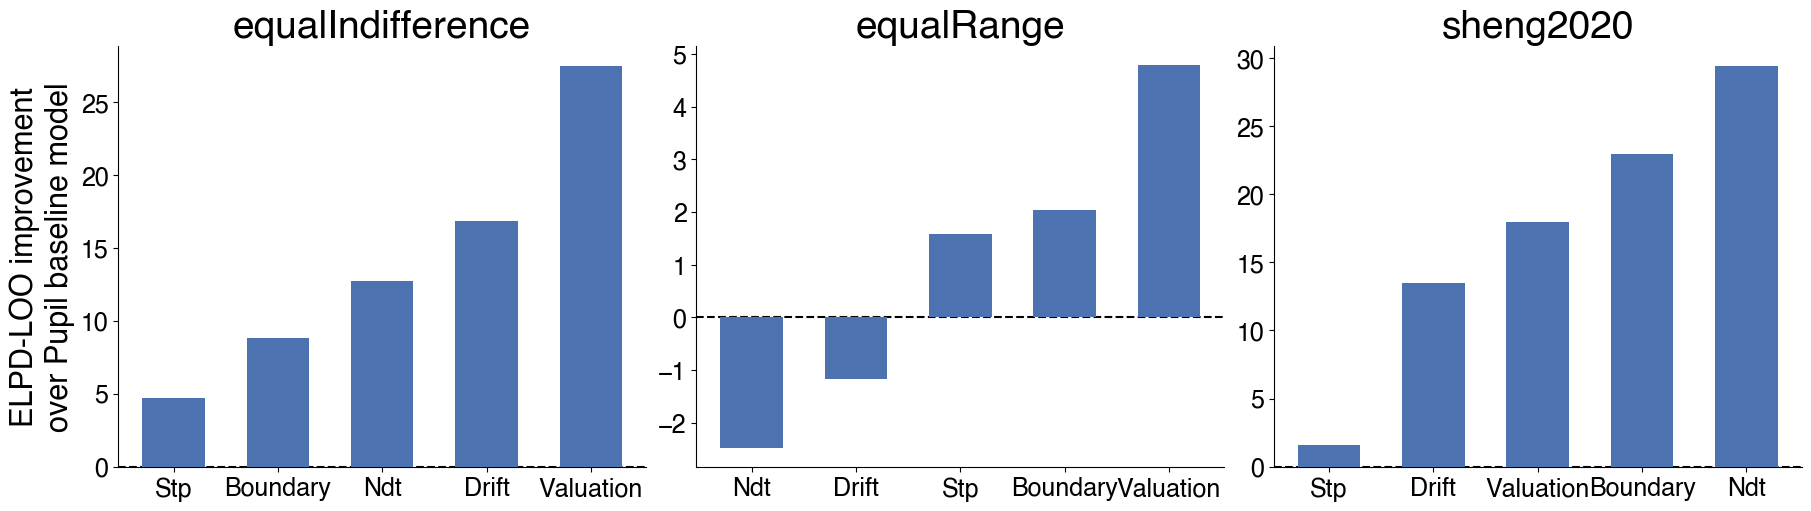

In [6]:
BASELINE_MODEL = "HDDM_Base_Lag1-stpdrift_Pupil"

ELPD_MODEL_ORDER = [
    ("HDDM_Base_Lag1-stpdrift_Pupil_stp",       "Stp"),
    ("HDDM_Base_Lag1-stpdrift_Pupil_valuation", "Valuation"),
    ("HDDM_Base_Lag1-stpdrift_Pupil_drift",     "Drift"),
    ("HDDM_Base_Lag1-stpdrift_Pupil_boundary",  "Boundary"),
    ("HDDM_Base_Lag1-stpdrift_Pupil_ndt",       "Ndt"),
]

BAR_COLOR = "#4C72B0"

elpd_vs_baseline = {}
for ds in DATASETS:
    loo = load_loo_comparison(ds, group_name="arousal_mechanisms").set_index("model")["elpd_loo"]
    baseline_elpd = loo[BASELINE_MODEL]
    elpd_vs_baseline[ds] = [loo[m] - baseline_elpd for m, _ in ELPD_MODEL_ORDER]

x_labels = [label for _, label in ELPD_MODEL_ORDER]

fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(18, 5), layout="constrained")

for col, ds in enumerate(DATASETS):
    ax = axes[col]
    plot_elpd_improvement(ax, elpd_vs_baseline[ds], x_labels, BAR_COLOR, show_ylabel=(col == 0))
    ax.set_title(DATASET_LABELS.get(ds, ds))

fig.savefig("saved/figure6.svg", dpi=300, bbox_inches="tight")
plt.show()